# 3. Does providing liquidity pay?

An LP in a constant-product pool is short volatility: arbitrageurs trade against the pool whenever the external price moves, and the LP bears the loss (**impermanent loss** versus holding; **LVR** versus a portfolio that rebalances at market prices). Fees are the compensation. This notebook measures the trade-off.

Closed forms used (fee-free, `r = S_T / S_0`): pool value `V0 sqrt(r)`, HODL value `V0 (1 + r)/2`, `IL(r) = 2 sqrt(r)/(1 + r) - 1`. For zero-drift GBM, `E[pool - HODL] = E[LVR] = -V0 (1 - exp(-sigma^2 T / 8))`.

Simulation: GBM external price, an arbitrageur moves the pool to the edge of the fee band after every step (closed form in `amm.arbitrage_to_price`), uninformed volume pays fees as a fixed fraction (`turnover`) of pool value per day.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, matplotlib.pyplot as plt, matplotlib as mpl
from amm import *
INK, INDIGO, AMBER, GREEN, CORAL, GREY = "#0E1A2B", "#4B3FE4", "#E8982B", "#0E9F7E", "#E5484D", "#8A94A6"
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "font.size": 10, "axes.grid": True, "grid.color": "#E3E7EE", "grid.linewidth": .7, "axes.axisbelow": True})

## Impermanent loss, full range versus concentrated

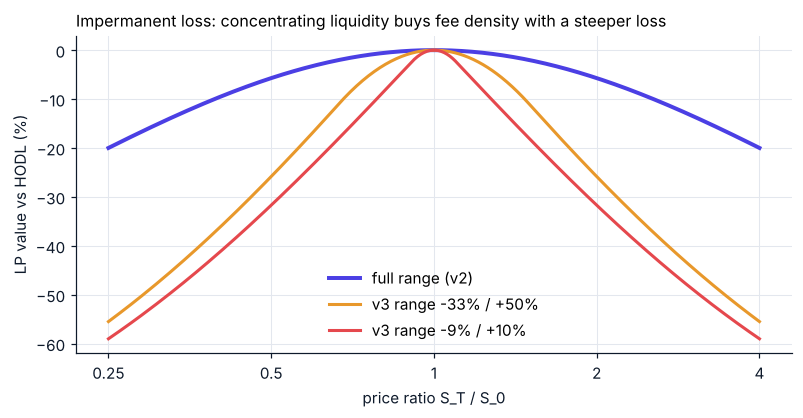

IL at 2x: -5.7191%, at 4x: -20.0000%
capital efficiency of range [1/1.5, 1.5]: 5.45x
capital efficiency of range [1/1.1, 1.1]: 21.49x


In [2]:
from amm import v3
r_ = np.linspace(0.25, 4, 600)
fig, ax = plt.subplots(figsize=(7.4, 3.9))
ax.plot(r_, impermanent_loss(r_) * 100, color=INDIGO, lw=2.6, label="full range (v2)")
for w, col in [(0.5, AMBER), (0.1, CORAL)]:
    ax.plot(r_, v3.il_versus_hodl(r_, 1.0, 1 / (1 + w), 1 + w) * 100, color=col, lw=2, label=f"v3 range -{w/(1+w)*100:.0f}% / +{w*100:.0f}%")
ax.set_xscale("log", base=2); ax.set_xticks([0.25, 0.5, 1, 2, 4]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4"])
ax.set_xlabel("price ratio S_T / S_0"); ax.set_ylabel("LP value vs HODL (%)"); ax.legend(frameon=False)
ax.set_title("Impermanent loss: concentrating liquidity buys fee density with a steeper loss", loc="left", fontsize=10.5)
fig.tight_layout(); fig.savefig("../assets/il_curve.png", dpi=150); plt.show()
print("IL at 2x: %.4f%%, at 4x: %.4f%%" % (impermanent_loss(2) * 100, impermanent_loss(4) * 100))
for w in (0.5, 0.1): print(f"capital efficiency of range [1/{1+w:.1f}, {1+w:.1f}]: {v3.concentration_factor(1.0, 1/(1+w), 1+w):.2f}x")

## Check: the Monte Carlo reproduces the closed forms (fee = 0)

In [3]:
sigma = 0.8
res0 = simulate_lp(sigma, fee=0.0, days=365, steps_per_day=2, n_paths=8000, seed=11)
s0 = summarise(res0)
print(f"E[LVR]/V0   simulated {s0['mean_lvr']:.5f} +/- {s0['se_lvr']:.5f}   closed form {expected_lvr_fraction(sigma, 1.0):.5f}")
print(f"E[pool-HODL] simulated {s0['mean_il']:.5f} +/- {s0['se_net']:.5f}   closed form {-expected_lvr_fraction(sigma, 1.0):.5f}")
r_end = res0["S"][:, -1]
print("max |pool/HODL - 1 - IL(r)| over paths: %.2e" % np.max(np.abs(res0["pool"][:, -1] / res0["hodl"][:, -1] - 1 - impermanent_loss(r_end))))

E[LVR]/V0   simulated 0.07719 +/- 0.00021   closed form 0.07688
E[pool-HODL] simulated -0.07620 +/- 0.00166   closed form -0.07688
max |pool/HODL - 1 - IL(r)| over paths: 2.78e-15


## Fan chart: 90 days, 80% volatility, 0.3% fee

turnover 0.02: mean net -1.009% +/- 0.070, mean fees 0.535%, mean LVR 1.579%, P(win) 0.500


turnover 0.15: mean net +2.470% +/- 0.070, mean fees 4.014%, mean LVR 1.579%, P(win) 0.868


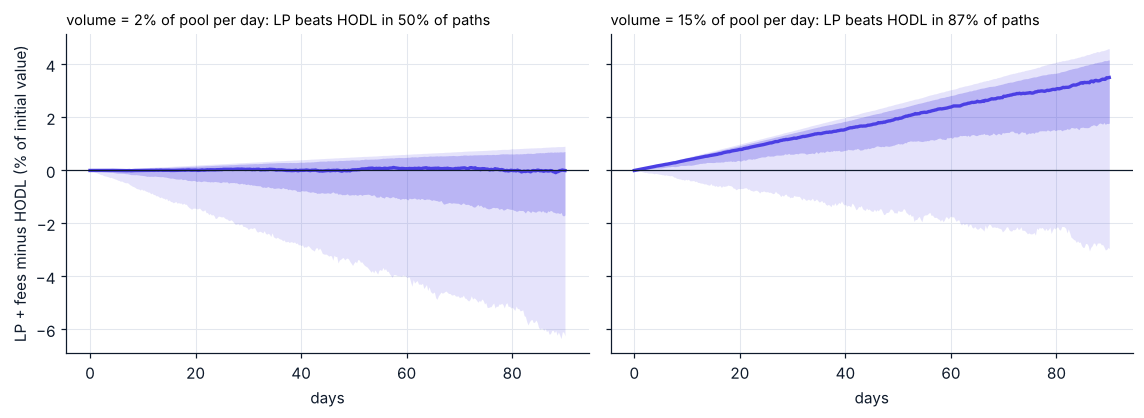

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
for ax, turn in zip(axes, (0.02, 0.15)):
    res = simulate_lp(0.8, 0.003, turnover=turn, days=90, steps_per_day=4, n_paths=1500, seed=5)
    q = np.percentile(res["net"], [5, 25, 50, 75, 95], axis=0) * 100; t_ = res["t_days"]
    ax.fill_between(t_, q[0], q[4], color=INDIGO, alpha=.14, lw=0); ax.fill_between(t_, q[1], q[3], color=INDIGO, alpha=.28, lw=0)
    ax.plot(t_, q[2], color=INDIGO, lw=2.2); ax.axhline(0, color=INK, lw=.8)
    s = summarise(res)
    ax.set_title(f"volume = {turn*100:.0f}% of pool per day: LP beats HODL in {s['p_lp_beats_hodl']*100:.0f}% of paths", loc="left", fontsize=9.5)
    ax.set_xlabel("days")
    print(f"turnover {turn:.2f}: mean net {s['mean_net']*100:+.3f}% +/- {s['se_net']*100:.3f}, mean fees {s['mean_fees']*100:.3f}%, mean LVR {s['mean_lvr']*100:.3f}%, P(win) {s['p_lp_beats_hodl']:.3f}")
axes[0].set_ylabel("LP + fees minus HODL (% of initial value)")
fig.tight_layout(); fig.savefig("../assets/lp_fan.png", dpi=150); plt.show()

## Where do fees beat the loss? Volatility x volume

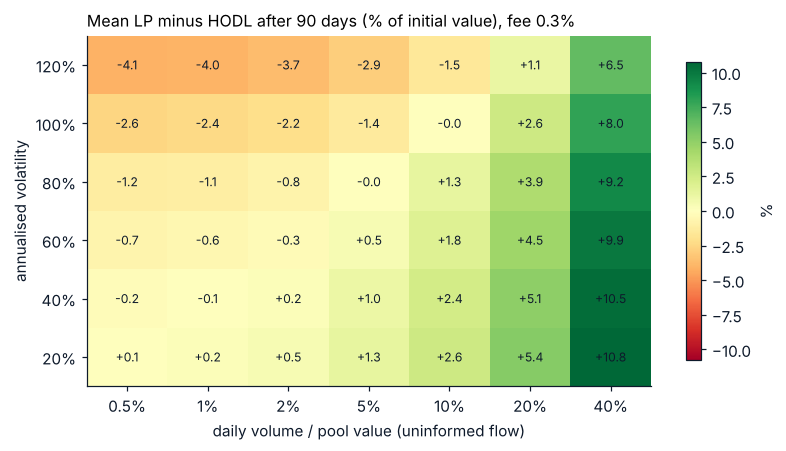

rule-of-thumb break-even daily turnover  sigma^2/(8*365*fee):
  sigma   20%  ->  0.46% of the pool per day
  sigma   40%  ->  1.83% of the pool per day
  sigma   60%  ->  4.11% of the pool per day
  sigma   80%  ->  7.31% of the pool per day
  sigma  100%  ->  11.42% of the pool per day
  sigma  120%  ->  16.44% of the pool per day


In [5]:
sigmas = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]; turns = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4]
grid = np.zeros((len(sigmas), len(turns)))
Zs = {}
for i, sg in enumerate(sigmas):
    for j, tu in enumerate(turns):
        grid[i, j] = summarise(simulate_lp(sg, 0.003, turnover=tu, days=90, steps_per_day=4, n_paths=600, seed=100 + i))["mean_net"] * 100
fig, ax = plt.subplots(figsize=(7.4, 4.2))
vmax = np.abs(grid).max()
im = ax.imshow(grid, origin="lower", cmap="RdYlGn", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks(range(len(turns))); ax.set_xticklabels([f"{t*100:g}%" for t in turns]); ax.set_yticks(range(len(sigmas))); ax.set_yticklabels([f"{s*100:.0f}%" for s in sigmas])
for i in range(len(sigmas)):
    for j in range(len(turns)): ax.text(j, i, f"{grid[i,j]:+.1f}", ha="center", va="center", fontsize=8, color=INK)
be = [(break_even_turnover(s, 0.003)) for s in sigmas]
ax.set_xlabel("daily volume / pool value (uninformed flow)"); ax.set_ylabel("annualised volatility"); ax.grid(False)
ax.set_title("Mean LP minus HODL after 90 days (% of initial value), fee 0.3%", loc="left", fontsize=10.5)
fig.colorbar(im, ax=ax, shrink=.85, label="%"); fig.tight_layout(); fig.savefig("../assets/lp_heatmap.png", dpi=150); plt.show()
print("rule-of-thumb break-even daily turnover  sigma^2/(8*365*fee):")
for s, b in zip(sigmas, be): print(f"  sigma {s*100:>4.0f}%  ->  {b*100:.2f}% of the pool per day")

## Does the rule of thumb locate the sign change? And fee tiers

In [6]:
print("sigma  rule-of-thumb   simulated break-even (mean net crosses 0, interpolated)")
for sg in (0.4, 0.8, 1.2):
    tus = np.array([0.005, 0.01, 0.02, 0.04, 0.08, 0.16, 0.32]); nets = np.array([summarise(simulate_lp(sg, 0.003, turnover=tu, days=90, steps_per_day=4, n_paths=800, seed=7))["mean_net"] for tu in tus])
    k = int(np.argmax(nets > 0)); x0, x1 = np.log(tus[k - 1]), np.log(tus[k]); be = np.exp(x0 + (0 - nets[k - 1]) / (nets[k] - nets[k - 1]) * (x1 - x0))
    print(f"{sg*100:>4.0f}%  {break_even_turnover(sg, 0.003)*100:>8.2f}%/day   {be*100:>8.2f}%/day")
print()
print("fee tier at 80% vol, 5% daily volume (same flow assumed at every tier):")
for fee in (0.0005, 0.003, 0.01):
    s = summarise(simulate_lp(0.8, fee, turnover=0.05, days=90, steps_per_day=4, n_paths=1500, seed=9))
    print(f"  fee {fee*100:.2f}%: mean net {s['mean_net']*100:+.3f}% +/- {s['se_net']*100:.3f}   fees {s['mean_fees']*100:.3f}%   LVR {s['mean_lvr']*100:.3f}%   P(beat HODL) {s['p_lp_beats_hodl']:.2f}")

sigma  rule-of-thumb   simulated break-even (mean net crosses 0, interpolated)


  40%      1.83%/day       1.35%/day


  80%      7.31%/day       6.41%/day


 120%     16.44%/day      16.01%/day

fee tier at 80% vol, 5% daily volume (same flow assumed at every tier):
  fee 0.05%: mean net -1.626% +/- 0.077   fees 0.224%   LVR 1.900%   P(beat HODL) 0.30
  fee 0.30%: mean net -0.200% +/- 0.076   fees 1.348%   LVR 1.598%   P(beat HODL) 0.65


  fee 1.00%: mean net +3.467% +/- 0.075   fees 4.507%   LVR 1.089%   P(beat HODL) 0.91


## Who earns what? A $40M ETH/USDC pool

Same assumptions as notebook 1: pool TVL $40M (10,000 ETH + 20,000,000 USDC at $2,000), arbitrage gas $6 per transaction (a trade is only sent if it earns more than that), hourly price steps, 90 days, volatility 80%, fee 0.3%, uninformed volume 5% of the pool per day. The LP is assumed to own the whole pool, so dollar figures are for the $40M.

- **Liquidity providers** earn fee income from uninformed volume and from the fees arbitrageurs pay (kept in the reserves), and lose **LVR**: value the pool gives up by trading at stale prices.
- **Arbitrageurs** earn the trade profit net of swap fees and gas.
- Validators earn the gas. Uninformed traders pay the fee plus price impact.

In [7]:
TVL, GAS_USD = 40e6, 6.0
rows = []
for gas_usd in (0.0, GAS_USD, 100.0):
    res = simulate_lp(0.8, 0.003, turnover=0.05, days=90, steps_per_day=24, n_paths=400, seed=21, gas=gas_usd / TVL)
    s = summarise(res); arb = res["arb_profit"][:, -1].mean() * TVL
    rows.append((gas_usd, s["mean_fees"] * TVL, s["mean_lvr"] * TVL, arb, s["mean_net"] * TVL, s["p_lp_beats_hodl"]))
print("arb gas $   LP fee income   LP loss vs rebalancing   arbitrageurs' net profit   LP minus HODL   P(LP beats HODL)")
for g, f_, l_, a_, n_, p_ in rows:
    print(f"{g:>9,.0f} {f_:>14,.0f} {l_:>22,.0f} {a_:>25,.0f} {n_:>15,.0f} {p_:>10.2f}")
print("(mean over 400 paths, 90 days, dollars; LP fee income here counts uninformed volume only)")

arb gas $   LP fee income   LP loss vs rebalancing   arbitrageurs' net profit   LP minus HODL   P(LP beats HODL)
        0        533,484                486,533                   486,533          15,660       0.67
        6        533,469                488,779                   480,380          13,415       0.67
      100        533,297                514,598                   423,716         -12,113       0.66
(mean over 400 paths, 90 days, dollars; LP fee income here counts uninformed volume only)
